# Lab 03-03 · Expectation, Variance and Functions of Random Variables

Companion to chapter [03-03](../../chapters/03-03-expectation-and-functions-of-rvs.md). Handout: [README.md](README.md).

Each part estimates expectations by sampling and compares them with the chapter's formulas. Cells marked **🔮 Predict** ask you to write a prediction *before* running. The seed is fixed, so your numbers will match the handout's.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
rng = np.random.default_rng(2026)
Q, Qinv, phi = stats.norm.sf, stats.norm.isf, stats.norm.pdf

## Part 1 — Averages converge to expectations

A packet fails with probability $p_e = 0.11308$ (Example 03-03.1) and is resent until it succeeds. Simulate 200,000 packets and track the running average of the number of transmissions.

theory: E[K] = 1.1275, sd = 0.3791
sample: mean = 1.1267, sd = 0.3779


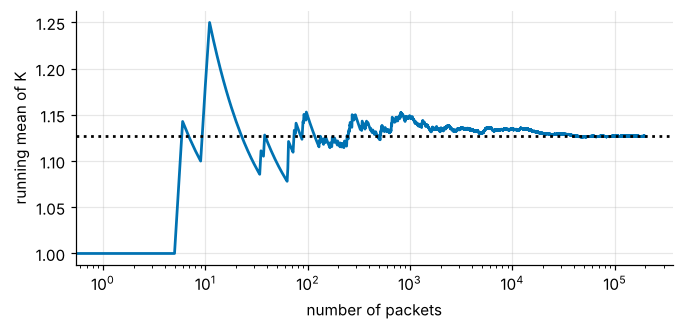

In [2]:
pe = -math.expm1(12_000 * math.log1p(-1e-5))
K = rng.geometric(1 - pe, 200_000)
running = np.cumsum(K) / np.arange(1, K.size + 1)
print(f"theory: E[K] = {1 / (1 - pe):.4f}, sd = {math.sqrt(pe) / (1 - pe):.4f}")
print(f"sample: mean = {K.mean():.4f}, sd = {K.std():.4f}")
plt.figure(figsize=(7, 3)); plt.semilogx(running); plt.axhline(1 / (1 - pe), color="k", ls=":")
plt.xlabel("number of packets"); plt.ylabel("running mean of K"); plt.show()

The running mean wanders at first and then settles on $1/q$: this is the **law of large numbers**, proved in 03-04. Its scatter after $n$ packets is about $\sigma_K/\sqrt n$.

## Part 2 — Linearity survives clustering

Simulate wafers of 400 center dies (yield 0.95) and 200 edge dies (yield 0.80), Example 03-03.2. In the *clustered* model, one wafer in ten is a "bad" wafer with yields 0.75 and 0.50, and the good wafers' yields are raised so that the average yields stay 0.95 and 0.80.

**🔮 Predict:** does clustering change the mean number of good dies per wafer? The standard deviation?

independent: mean 539.99, sd 7.118   (theory 540, 7.141)
clustered  : mean 540.04, sd 47.106


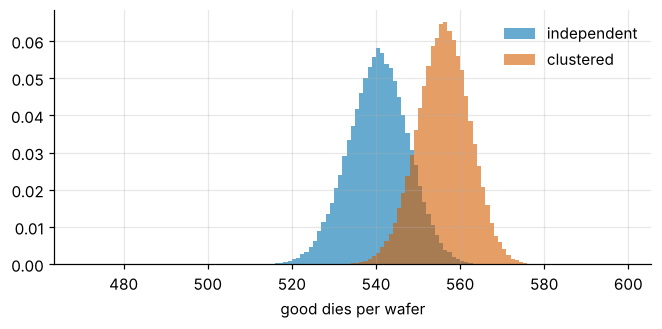

In [3]:
W = 100_000
indep = rng.binomial(400, 0.95, W) + rng.binomial(200, 0.80, W)
bad = rng.random(W) < 0.1
yc = np.where(bad, 0.75, (0.95 - 0.1 * 0.75) / 0.9)
ye = np.where(bad, 0.50, (0.80 - 0.1 * 0.50) / 0.9)
clus = rng.binomial(400, yc) + rng.binomial(200, ye)
print(f"independent: mean {indep.mean():.2f}, sd {indep.std():.3f}   (theory 540, {math.sqrt(51):.3f})")
print(f"clustered  : mean {clus.mean():.2f}, sd {clus.std():.3f}")
plt.figure(figsize=(7, 3))
plt.hist(indep, bins=range(470, 600), density=True, alpha=0.6, label="independent")
plt.hist(clus, bins=range(470, 600), density=True, alpha=0.6, label="clustered")
plt.xlabel("good dies per wafer"); plt.legend(); plt.show()

The means agree, because linearity of expectation needs no independence. The spread is more than six times larger with clustering, and the distribution grows a second hump from the bad wafers: planning that assumes independent dies will understate the risk of a bad week.

## Part 3 — Power is DC plus AC

Sample the inductor current of Example 03-03.3 (10 A average, 3 A peak-to-peak triangular ripple) at random times, and a sinusoid with a random phase.

In [4]:
t = rng.random(1_000_000)                        # random instants within one period
tri = 1.5 * (4 * np.abs(t - 0.5) - 1)            # triangle wave, peak 1.5 A
i = 10 + tri
print(f"mean {i.mean():.4f} A, variance {i.var():.4f} A^2 (theory 0.75), mean square {np.mean(i**2):.3f} A^2")
print(f"RMS {math.sqrt(np.mean(i**2)):.4f} A  (theory {math.sqrt(100.75):.4f})")
theta = rng.uniform(0, 2 * np.pi, 1_000_000)
s = 2.0 * np.cos(theta)
print(f"random-phase sinusoid, amplitude 2: mean {s.mean():.4f}, mean square {np.mean(s**2):.4f} (theory 2)")

mean 9.9997 A, variance 0.7500 A^2 (theory 0.75), mean square 100.745 A^2
RMS 10.0372 A  (theory 10.0374)
random-phase sinusoid, amplitude 2: mean 0.0004, mean square 1.9970 (theory 2)


## Part 4 — Functions of a random variable

Square Gaussian samples (a power detector, Example 03-03.5) and exponentiate them (log-normal leakage, Example 03-03.6).

**🔮 Predict:** what fraction of instantaneous noise-power samples exceeds 4 times the average? By how much does the mean leakage exceed the median?

power: mean 1.0008 (theory 1), sd/mean 1.4150 (theory 1.4142)
P(Y > 4): measured 0.04558, theory 2Q(2) = 0.04550
leakage: median 1.0013, mean 1.2704 (theory 1.2694)


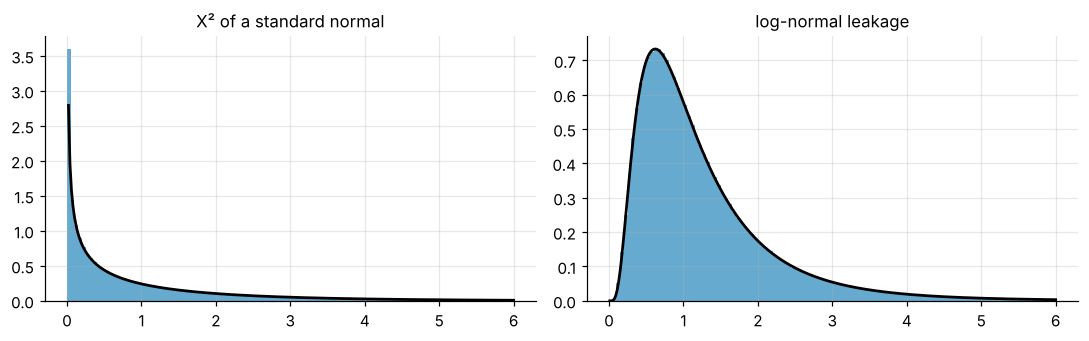

In [5]:
x = rng.standard_normal(1_000_000)
y = x**2
print(f"power: mean {y.mean():.4f} (theory 1), sd/mean {y.std() / y.mean():.4f} (theory {math.sqrt(2):.4f})")
print(f"P(Y > 4): measured {np.mean(y > 4):.5f}, theory 2Q(2) = {2 * Q(2):.5f}")
VT = 1.380649e-23 * 300 / 1.602176634e-19
s_ln = 0.025 / (1.4 * VT)
leak = np.exp(s_ln * x)
print(f"leakage: median {np.median(leak):.4f}, mean {leak.mean():.4f} (theory {math.exp(s_ln**2 / 2):.4f})")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
yy = np.linspace(0.02, 6, 300)
ax[0].hist(y, bins=120, range=(0, 6), density=True, alpha=0.6)
ax[0].plot(yy, np.exp(-yy / 2) / np.sqrt(2 * np.pi * yy), "k"); ax[0].set_title("X² of a standard normal")
ll = np.linspace(0.01, 6, 300)
ax[1].hist(leak, bins=120, range=(0, 6), density=True, alpha=0.6)
ax[1].plot(ll, stats.lognorm.pdf(ll, s_ln), "k"); ax[1].set_title("log-normal leakage")
fig.tight_layout(); plt.show()

## Part 5 — Chebyshev versus reality

Four distributions with mean 0 and variance 1: uniform, Gaussian, Laplace (heavier tails), and the three-point distribution that puts probability $1/18$ at each of $\pm3$ and the rest at 0.

**🔮 Predict:** which one comes closest to the Chebyshev bound $P(|X| \ge 3) \le 1/9$?

In [6]:
N = 2_000_000
samples = {
    "uniform": rng.uniform(-math.sqrt(3), math.sqrt(3), N),
    "Gaussian": rng.standard_normal(N),
    "Laplace": rng.laplace(0, 1 / math.sqrt(2), N),
    "three-point": rng.choice([-3.0, 0.0, 3.0], N, p=[1 / 18, 8 / 9, 1 / 18]),
}
for name, z in samples.items():
    print(f"{name:12s}: var {z.var():.3f}   P(|X| >= 3) = {np.mean(np.abs(z) >= 3):.5f}   (Chebyshev bound {1 / 9:.5f})")

uniform     : var 1.000   P(|X| >= 3) = 0.00000   (Chebyshev bound 0.11111)
Gaussian    : var 1.001   P(|X| >= 3) = 0.00271   (Chebyshev bound 0.11111)
Laplace     : var 1.003   P(|X| >= 3) = 0.01448   (Chebyshev bound 0.11111)
three-point : var 1.002   P(|X| >= 3) = 0.11129   (Chebyshev bound 0.11111)


The three-point distribution meets the bound exactly: Chebyshev cannot be improved without more information. Every smooth, unimodal distribution does far better, and even the heavier-tailed Laplace stays below the bound by a factor of almost 8.

## Part 6 — PAPR of OFDM and of DFT-spread OFDM

Build OFDM symbols with 256 QPSK subcarriers in a 1024-point inverse FFT (4× oversampling, so the samples catch the peaks), and a DFT-spread version (a 256-point DFT before the subcarrier mapping, as in the LTE uplink and the NR uplink option).

**🔮 Predict:** the OFDM PAPR at $10^{-4}$ (compare with 9.643 dB). How much lower is the DFT-spread version?

OFDM      : PAPR at 1e-2 6.61 dB, at 1e-4 9.60 dB
DFT-spread: PAPR at 1e-2 4.51 dB, at 1e-4 6.67 dB
complex Gaussian theory: 6.632 dB and 9.643 dB


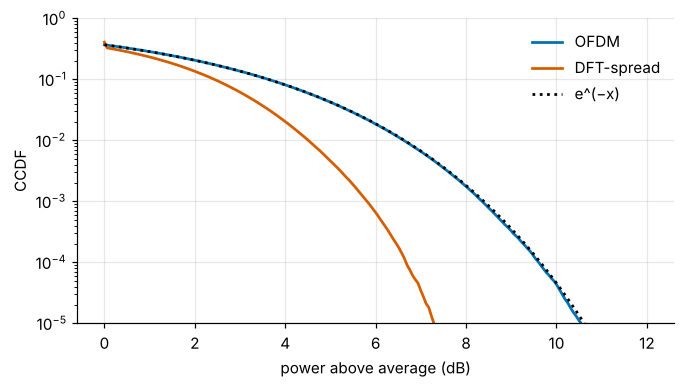

In [7]:
M, Nfft, S = 256, 1024, 4000
def qpsk(n):
    return ((2 * rng.integers(0, 2, n) - 1) + 1j * (2 * rng.integers(0, 2, n) - 1)) / math.sqrt(2)
def modulate(X):
    grid = np.zeros((X.shape[0], Nfft), complex)
    grid[:, :M // 2] = X[:, M // 2:]; grid[:, -M // 2:] = X[:, :M // 2]   # occupied band centred on DC
    return np.fft.ifft(grid, axis=1)
d = qpsk(S * M).reshape(S, M)
ofdm = modulate(d)
dfts = modulate(np.fft.fftshift(np.fft.fft(d, axis=1), axes=1))
def papr_at(sig, p):
    pw = np.abs(sig.ravel())**2; pw /= pw.mean()
    return 10 * math.log10(np.quantile(pw, 1 - p))
for name, sig in (("OFDM", ofdm), ("DFT-spread", dfts)):
    print(f"{name:10s}: PAPR at 1e-2 {papr_at(sig, 1e-2):.2f} dB, at 1e-4 {papr_at(sig, 1e-4):.2f} dB")
print(f"complex Gaussian theory: {10 * math.log10(math.log(1e2)):.3f} dB and {10 * math.log10(math.log(1e4)):.3f} dB")
xdb = np.linspace(0, 12, 200)
plt.figure(figsize=(7, 3.6))
for name, sig in (("OFDM", ofdm), ("DFT-spread", dfts)):
    pw = np.abs(sig.ravel())**2; pw /= pw.mean()
    plt.semilogy(xdb, [np.mean(pw > 10**(v / 10)) for v in xdb], label=name)
plt.semilogy(xdb, np.exp(-10**(xdb / 10)), "k:", label="e^(−x)")
plt.ylim(1e-5, 1); plt.xlabel("power above average (dB)"); plt.ylabel("CCDF"); plt.legend(); plt.show()

The OFDM CCDF hugs the complex-Gaussian curve $e^{-x}$, as the central-limit argument predicts. DFT spreading turns the transmitted samples back into an interpolated version of the QPSK symbols, cutting the PAPR at $10^{-4}$ by about 3 dB. That is the reason for SC-FDMA in the LTE uplink (§9).

## Part 7 — Loading an ADC

Quantize Gaussian samples with an 8-bit converter of full scale $\pm k\sigma$, including clipping, and measure the SNR.

**🔮 Predict:** the best loading factor for 8 bits, and what happens at $k = 3$.

In [8]:
def snr_formula(nb, k):
    return -10 * math.log10(k * k / (3 * 4.0**nb) + 2 * ((1 + k * k) * Q(k) - k * phi(k)))
def snr_measured(nb, k, x):
    delta = 2 * k / 2**nb
    q = np.clip(np.floor(x / delta) * delta + delta / 2, -k + delta / 2, k - delta / 2)   # mid-rise quantizer with clipping
    return 10 * math.log10(np.mean(x**2) / np.mean((x - q)**2))
x = rng.standard_normal(2_000_000)
ks = np.arange(2.5, 6.51, 0.5)
for k in ks:
    print(f"k = {k:.1f}: measured {snr_measured(8, k, x):6.2f} dB, formula {snr_formula(8, k):6.2f} dB")
from scipy.optimize import minimize_scalar
opt = minimize_scalar(lambda k: -snr_formula(8, k), bounds=(2, 8), method="bounded")
print(f"optimum k = {opt.x:.3f}, SNR = {-opt.fun:.2f} dB")

k = 2.5: measured  26.03 dB, formula  26.14 dB
k = 3.0: measured  33.26 dB, formula  33.44 dB
k = 3.5: measured  39.00 dB, formula  39.27 dB
k = 4.0: measured  40.50 dB, formula  40.58 dB
k = 4.5: measured  39.84 dB, formula  39.85 dB
k = 5.0: measured  38.95 dB, formula  38.96 dB
k = 5.5: measured  38.12 dB, formula  38.13 dB
k = 6.0: measured  37.36 dB, formula  37.37 dB
k = 6.5: measured  36.67 dB, formula  36.68 dB
optimum k = 3.924, SNR = 40.60 dB


Measurement and formula agree to within about 0.3 dB (closest where granular noise dominates; the real quantizer's last level sits half a step inside $\pm k$), and the optimum sits near $k = 3.9$. At $k = 3$, clipping costs about 7 dB relative to the optimum.

## Your turn

1. In Part 7, repeat for 12 bits. Where is the optimum now, and how much SNR does a 12-bit ADC lose if it is loaded at the 8-bit optimum?
2. In Part 6, clip the OFDM signal at 8 dB above its average power and measure the fraction of power clipped. Compare with $e^{-x}$ at $x = 10^{0.8}$ (Problem 03-03.16).